\begin{equation}
    \hbar k_\parallel = \sqrt{2m_e E_{kin}}\sin\theta
\end{equation}

\begin{equation}
    k_\parallel \approx 0.5123\sqrt{E_{kin}}\sin\theta
\end{equation}

In [25]:
from igor2 import binarywave
import numpy as np
import P04_Parser

def load_ibw_swept_as_kmap(file):
    """Swept (2D) .ibw cut -> Kmap with 3 identical theta_y slices, so P04_Parser plotting works."""
    wave = binarywave.load(file)["wave"]
    data = np.array(wave["wData"], dtype=float)     # (energy, angle)
    sfa = wave["wave_header"]["sfA"]
    sfb = wave["wave_header"]["sfB"]
    energy = sfb[0] + sfa[0] * np.arange(data.shape[0])
    theta = sfb[1] + sfa[1] * np.arange(data.shape[1])
    data_map = np.repeat(data[:, :, np.newaxis], 3, axis=2)
    return P04_Parser.Kmap(data_map, energy, theta, np.array([-1, 0, 1]))

In [26]:
import os

file_dir = r"T:\Beamtimes\MaxIV\Oct_26\raw\FeSi_2B_49eV_LV_temp_series"
files = os.listdir(file_dir)

files_names_fesi = [f for f in files if f.endswith(".ibw") and "testing" not in f and not f.startswith("TaFoil")]
files = [os.path.join(file_dir, f) for f in files_names_fesi]


labels = {f: f[20:-14] for f in files_names_fesi} #[20:-14] for FeSi and [19:-17] for TaFoil
labels

{'FeSi_2B_hv_49_LV_GX_100K_0001Swept.ibw': '100K',
 'FeSi_2B_hv_49_LV_GX_100K_down_0001Swept.ibw': '100K_down',
 'FeSi_2B_hv_49_LV_GX_200K_0001Swept.ibw': '200K',
 'FeSi_2B_hv_49_LV_GX_20K_0001Swept.ibw': '20K',
 'FeSi_2B_hv_49_LV_GX_20K_down_0001Swept.ibw': '20K_down',
 'FeSi_2B_hv_49_LV_GX_60K_0001Swept.ibw': '60K',
 'FeSi_2B_hv_49_LV_GX_60K_down_0001Swept.ibw': '60K_down'}

In [27]:
data.shape

(501, 700, 3)

Non-down: [20.0, 60.0, 100.0, 200.0]
Down: [20.0, 60.0, 100.0]


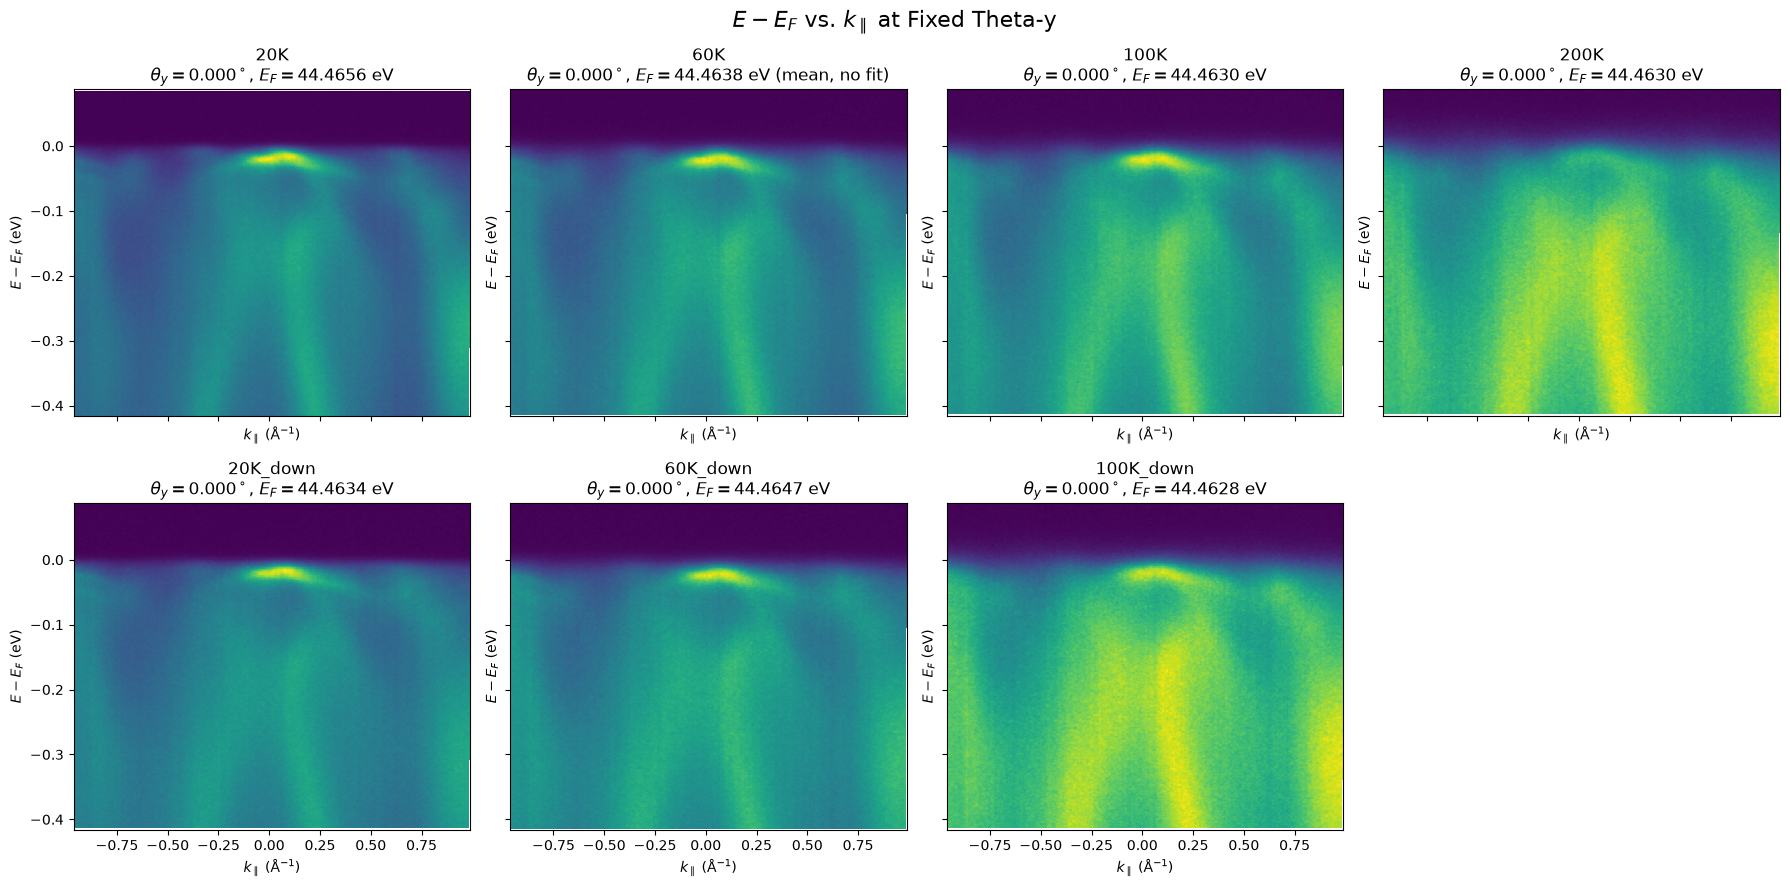

In [28]:
import re
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

theta_y_value = 0

# Fermi level fits from the Ta foil reference, [E_F, sigma E_F, label]
fermi_levels = [
    [44.46561573097595, 4.416108643800504e-05, "20K"],
    [44.46339683235221, 4.760890885292209e-05, "20K down"],
    [44.46474340943516, 6.086142595726613e-05, "60K down"],
    [44.4630362039962, 8.999601967624399e-05, "100K"],
    [44.46276134333432, 8.070021295226096e-05, "100K down"],
    [44.46300357260092, 0.00011011127018113597, "200K"],
]
E_F_of = {lab: ef for ef, _, lab in fermi_levels}
# No Ta foil reference was fitted for 60K (up), so fall back to the mean of the fitted values
E_F_fallback = np.mean([ef for ef, _, _ in fermi_levels])

def fermi_level(file):
    """E_F for a FeSi file, matched on its label ('100K_down' -> '100K down')."""
    lab = labels[Path(file).name].replace("_", " ")
    if lab in E_F_of:
        return E_F_of[lab], False
    return E_F_fallback, True

def temperature(file):
    match = re.search(r"(\d+(?:\.\d+)?)\s*K", Path(file).name)
    return float(match.group(1)) if match else float("inf")

def is_down(file):
    return "down" in Path(file).stem.lower()

def theta_to_k(theta, E_kin):
    """k_par (1/Å) from theta in degrees and kinetic energy (eV). Broadcasts over both."""
    return 0.5123 * np.sqrt(E_kin) * np.sin(np.deg2rad(theta))

non_down_files = sorted(
    [file for file in files if not is_down(file)],
    key=temperature,
)

down_files = sorted(
    [file for file in files if is_down(file)],
    key=temperature,
)

print("Non-down:", [temperature(file) for file in non_down_files])
print("Down:", [temperature(file) for file in down_files])

fig, axes = plt.subplots(
    2,
    4,
    figsize=(18, 9),
    sharex=True,
    sharey=True,
)

for row, selected_files in enumerate([non_down_files, down_files]):
    for column, file in enumerate(selected_files):
        data = load_ibw_swept_as_kmap(file)

        theta_y_index = np.argmin(
            np.abs(data.phi - theta_y_value)
        )

        ax = axes[row, column]

        E_F, is_fallback = fermi_level(file)

        # k depends on both theta and the kinetic energy of each row, so the grid is 2D (energy, theta)
        theta_grid, energy_grid = np.meshgrid(data.theta, data.energy)

        ax.pcolormesh(
            theta_to_k(theta_grid, energy_grid),  # k must use the kinetic energy, not E - E_F
            energy_grid - E_F,
            data.data[:, :, theta_y_index],
            shading="auto",
        )

        ax.set_title(
            f"{labels[Path(file).name]}\n"
            rf"$\theta_y={data.phi[theta_y_index]:.3f}^\circ$, "
            rf"$E_F={E_F:.4f}$ eV" + (" (mean, no fit)" if is_fallback else "")
        )
        ax.set_xlabel(r"$k_\parallel$ (Å$^{-1}$)")
        ax.set_ylabel(r"$E - E_F$ (eV)")

# Hide unused subplot, since there is no 200 K down scan
for column in range(len(down_files), 4):
    axes[1, column].set_visible(False)

fig.suptitle(r"$E - E_F$ vs. $k_\parallel$ at Fixed Theta-y", fontsize=16)
fig.tight_layout()
plt.show()

In [ ]:
a=4.49

In [29]:
energy_grid.shape

(501, 700)